Solver success: True
Capacitor voltage at 5 s: 11.8295 V
Maximum error against exact solution: 2.138e-09 V


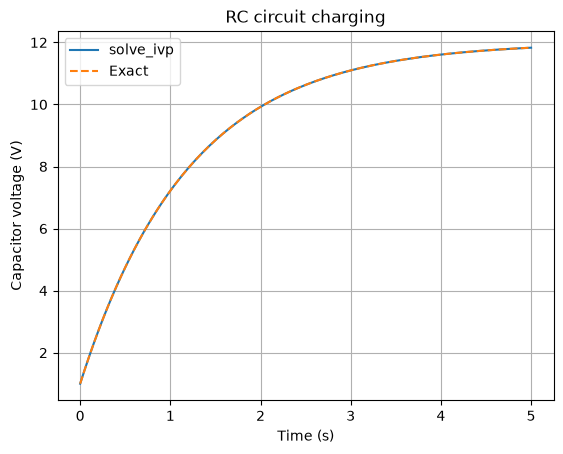

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

#Q. Numerical Solution of ODEs Using SciPy

# RC charging circuit:
# dV/dt = (Vs - V)/(R*C)
Vs = 12.0          # supply voltage (V)
R = 1500.0         # resistance (ohms)
C = 0.0008         # capacitance (farads)
V0 = 1.0           # initial capacitor voltage

def rc_circuit(t, V):
    return [(Vs - V[0]) / (R * C)]

t_eval = np.linspace(0, 5, 200)

solution = solve_ivp(
    rc_circuit,
    (0, 5),
    [V0],
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)

# Exact RC charging curve for validation
exact = Vs + (V0 - Vs) * np.exp(-solution.t / (R * C))

print("Solver success:", solution.success)
print(f"Capacitor voltage at 5 s: {solution.y[0, -1]:.4f} V")
print(f"Maximum error against exact solution: {np.max(np.abs(solution.y[0]-exact)):.3e} V")

plt.plot(solution.t, solution.y[0], label="solve_ivp")
plt.plot(solution.t, exact, linestyle="--", label="Exact")
plt.xlabel("Time (s)")
plt.ylabel("Capacitor voltage (V)")
plt.title("RC circuit charging")
plt.legend()
plt.grid(True)
plt.show()